# Tritium production in a PbLi concentric-spheres model

<!-- index:description -->
Demonstrate setting up and running an OpenMC simulation using a simple concentric-sphere geometry with a lead–lithium (PbLi) breeding blanket.
<!-- /index:description -->

<!-- generated:structure -->
```text
Tritium production in a PbLi concentric-spheres model
├── 1. Materials
├── 2. Geometry
├── 3. Settings (with source)
├── 4. Tally
├── 5. Ready and plot
├── 6. Run
└── 7. Output
```
<!-- /generated:structure -->

Following a data-science-oriented approach, material compositions and geometric specifications are organized in pandas DataFrames, from which OpenMC objects are constructed programmatically. This minimizes repetitive code, reduces the risk of inconsistencies, and makes the model easier to modify and validate.

The example originated from the [Fusion Energy Neutronics Workshop](https://github.com/fusion-energy/neutronics-workshop/blob/main/tasks/task_05_CSG_cell_tally_TBR/1_example_tritium_production.ipynb), although the original code has since been extensively reworked—perhaps beyond recognition.

In [1]:
import re

import openmc
import pandas as pd

from openmc_workbench_config import DATA_ROOT

xs_xml = DATA_ROOT / 'endf-b8.1' / 'cross_sections.xml'
openmc.config['cross_sections'] = xs_xml

## 1. Materials

In [2]:
# https://docs.openmc.org/en/stable/pythonapi/generated/openmc.Material.html
mats_df = pd.DataFrame(columns=[
    'name', 'element', 'percent', 'percent_type',
    'enrichment', 'enrichment_target', 'enrichment_type'
])
mats_df.loc[len(mats_df)] = ['breeder', 'Pb', 84.2, 'ao'] + 3 * [None]
mats_df.loc[len(mats_df)] = ['breeder', 'Li', 15.8, 'ao', 50, 'Li6', 'ao']
mats_df.loc[len(mats_df)] = ['steel', 'Fe', 0.95, 'wo'] + 3 * [None]
mats_df.loc[len(mats_df)] = ['steel', 'C', 0.05, 'wo'] + 3 * [None]
mats_df

,name,element,percent,percent_type,enrichment,enrichment_target,enrichment_type
0,breeder,Pb,84.20,ao,None,None,None
1,breeder,Li,15.80,ao,50,Li6,ao
2,steel,Fe,0.95,wo,None,None,None
3,steel,C,0.05,wo,None,None,None


In [3]:
mats_dic = {}
for name, dat in mats_df.groupby('name'):
    mats_dic[name] = openmc.Material()

    for _, row in dat.drop(columns='name').iterrows():
        mats_dic[name].add_element(**row.dropna().to_dict())

mats_dic['breeder'].set_density('atom/b-cm', 3.2720171e-2)
mats_dic['steel'].set_density('g/cm3', 7.75)
mats_dic

{'breeder': Material
 	ID             =	1
 	Name           =	
 	Temperature    =	None
 	Density        =	0.032720171 [atom/b-cm]
 	Volume         =	None [cm^3]
 	Depletable     =	False
 	S(a,b) Tables  
 	Nuclides       
 	Pb204          =	1.1788       [ao]
 	Pb206          =	20.2922      [ao]
 	Pb207          =	18.6082      [ao]
 	Pb208          =	44.1208      [ao]
 	Li6            =	7.9          [ao]
 	Li7            =	7.9          [ao],
 'steel': Material
 	ID             =	2
 	Name           =	
 	Temperature    =	None
 	Density        =	7.75 [g/cm3]
 	Volume         =	None [cm^3]
 	Depletable     =	False
 	S(a,b) Tables  
 	Nuclides       
 	Fe54           =	0.053632803115715125 [wo]
 	Fe56           =	0.8730645234058433 [wo]
 	Fe57           =	0.020523501829909044 [wo]
 	Fe58           =	0.002779171648532559 [wo]
 	C12            =	0.04940034225428433 [wo]
 	C13            =	0.0005996577457156737 [wo]}

In [4]:
model = {}
model['materials'] = openmc.Materials(mats_dic.values())

## 2. Geometry

In [5]:
geom_df = pd.DataFrame(
    columns=['radius_cm', 'boundary_type', 'region', 'mats']
)
geom_df.loc['vessel_inner'] = [500, None, '-vessel_inner', None]
geom_df.loc['first_wall'] = [510, None, '-first_wall & +vessel_inner', 'steel']
geom_df.loc['breeder_blanket'] = [
    610, 'vacuum', '+first_wall & -breeder_blanket', 'breeder'
]
geom_df

,radius_cm,boundary_type,region,mats
vessel_inner,500,None,-vessel_inner,None
first_wall,510,None,-first_wall & +vessel_inner,steel
breeder_blanket,610,vacuum,+first_wall & -breeder_blanket,breeder


In [6]:
# Ensure that all surfaces referenced in region expressions are defined in geom_df.index.
assert all(
    name in geom_df.index
    for region in geom_df['region']
    for name in re.findall(r'\b\w+\b', region)
)

In [7]:
sphere = {}
for name, dat in geom_df.iterrows():
    sphere[name] = openmc.Sphere(
        r=dat['radius_cm'],
        **dat[['boundary_type']].dropna().to_dict()
    )

In [8]:
# Convert named surface expressions into OpenMC regions.
# https://docs.openmc.org/en/stable/pythonapi/generated/openmc.Region.html

surfaces = {s.id: s for s in sphere.values()}

def str2region(string):
    for name, surface in sphere.items():
        string = string.replace(name, str(surface.id))

    string = string.replace('&', ' ')

    return openmc.Region.from_expression(string, surfaces)

geom = {}
for name, dat in geom_df.iterrows():
    geom[name] = openmc.Cell(
        name=name,
        region=str2region(dat['region']),
        fill=mats_dic.get(dat['mats'])
    )

model['geometry'] = openmc.Geometry(geom.values())


## 3. Settings (with source)

In [9]:
model['settings'] = openmc.Settings()
model['settings'].batches = 10
model['settings'].particles = 10000
model['settings'].run_mode = 'fixed source'

model['settings'].source = openmc.IndependentSource(
    space=openmc.stats.Point((0, 0, 0)),
    angle=openmc.stats.Isotropic(),
    energy=openmc.stats.Discrete([14e6], [1])
)

## 4. Tally

In [10]:
model['tallies'] = openmc.Tallies([
    openmc.Tally(
        name='TBR',
        filters=[openmc.CellFilter(geom['breeder_blanket'])],
        scores=['H3-production'],
        nuclides=['Li6', 'Li7'],
    )
])

## 5. Ready and plot

<Axes: xlabel='x [cm]', ylabel='y [cm]'>

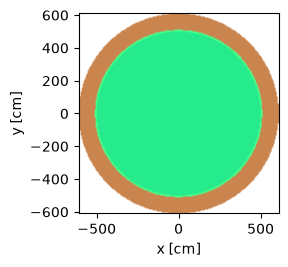

In [11]:
openmc_model = openmc.Model(**model)
openmc_model.plot()

## 6. Run

In [12]:
sp_filename = openmc_model.run()

                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

## 7. Output

In [13]:
with openmc.StatePoint(sp_filename) as sp:
    tbr_tally = sp.get_tally(name='TBR')
    df = tbr_tally.get_pandas_dataframe()
df

,cell,nuclide,score,mean,std. dev.
0,3,Li6,"(n,Xt)",1.022352,0.005165
1,3,Li7,"(n,Xt)",0.003615,0.000027
